# HT-9046MX — ML Comparison: Minute-Only vs Second-Derived Response Features

Notebook สำหรับทดสอบว่า feature ที่สกัดจาก raw log ระดับหนึ่งวินาทีเพิ่มคุณค่าให้โมเดล anomaly ระดับ event หรือไม่
พร้อมประเมินต้นทุนและข้อจำกัดเมื่อนำไปรันจริงบน Server

> ขอบเขตสำคัญ: ไม่มี technician-confirmed failure labels ดังนั้นผลนี้วัด **ความเสถียร การถ่ายโอน และ sensitivity**
> ไม่ใช่ accuracy/recall ของ leak classifier

## tl;dr

เปรียบเทียบสามแบบบน closing-event rows ชุดเดียวกัน 240 events: train 160, temporal test 73 และ sparse external 7 events

1. **Minute-only** — relative baseline, differential, rolling slope และ minute lag เดิม
2. **Hybrid fast 30 s** — Minute-only + response ที่พร้อมภายใน 30 วินาที
3. **Hybrid complete 120 s** — Hybrid fast + peak, lag, hunting และ response 60/120 วินาที

- Temporal alert-candidate rate: **2.74% / 4.11% / 5.48%** ตามลำดับ เทียบ train reference 5%
- ใน synthetic response-shape stress test โมเดล minute-only ไม่เห็นการเปลี่ยน ส่วน hybrid fast/complete มี median anomaly score เพิ่ม **+0.035 / +0.046**
- Complete model ไวที่สุด แต่มีความเสี่ยงจากข้อมูลน้อย: 58 features ต่อ train 160 events และ MX081 LOMO มีเพียง n=3 แต่ถูก flag 100%
- Server ไม่ใช่ bottleneck หลัก: model bundle ประมาณ 1.2–1.4 MiB, batch 8 p95 ต่ำกว่า 50 ms ในเครื่องทดสอบ และ ring-buffer payload สำหรับ 19 เครื่องประมาณ 2.5 MiB

**คำแนะนำ:** ใช้ Minute-only เป็น continuous monitor, Hybrid fast เป็น event watch และ Hybrid complete เป็น confirmation ใน shadow mode
จนกว่าจะมี event ครอบคลุม SV On/opening และ technician-confirmed labels มากขึ้น

## Context & Methods

### Decision

ต้องตัดสินว่า production server ควรใช้โมเดลรายนาทีเดิม, เปลี่ยนเป็น second-derived model ทั้งหมด
หรือใช้สองชั้นร่วมกันโดยให้โมเดลรายนาทีเฝ้าต่อเนื่องและ second-derived model ทำงานเฉพาะ `ChangeValve` event

### Key assumptions and limits

- ใช้ `README_System.md` เป็น Data Contract
- เปรียบเทียบเฉพาะ machine × module × SV เดียวกัน และใช้ qualified closing events เท่านั้น
- event minute ถูกจับคู่กับ **qualified minute ก่อนหน้าเท่านั้น** ด้วย backward as-of join; ไม่ใช้ข้อมูลอนาคต
- second-derived feature ที่ 60/120 วินาทีมี online latency ตามจริง
- `Hp_2nd = 180–230 psi` เป็น qualified field reference; `<180 psi` เป็น screening evidence ไม่ใช่ label และ `>=180 psi` ไม่เพิ่ม undercharge score
- timestamps ในไฟล์ไม่มี timezone metadata จึงแสดงเป็น naive timestamps ตาม source

## Data

### 1. Setup and locate reviewed artifacts

In [1]:
import importlib.util
import json
import math
import subprocess
import sys
import time
from pathlib import Path

required = {
    "numpy": "numpy", "pandas": "pandas", "polars": "polars",
    "matplotlib": "matplotlib", "seaborn": "seaborn",
    "sklearn": "scikit-learn", "joblib": "joblib", "scipy": "scipy",
}
missing = [pip_name for module, pip_name in required.items() if importlib.util.find_spec(module) is None]
if missing:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", *missing])

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import polars as pl
import seaborn as sns
from scipy.stats import spearmanr
from sklearn.ensemble import IsolationForest
from sklearn.preprocessing import RobustScaler
from IPython.display import Markdown, display

PROJECT_ROOT_OVERRIDE = ""
DATASET_NAME = "HT9046MX-20260902T013607Z-1-001"

def find_project_root():
    candidates = [Path(PROJECT_ROOT_OVERRIDE)] if PROJECT_ROOT_OVERRIDE else []
    candidates += [Path.cwd(), Path.cwd().parent, Path("/content/OPERATION_P"), Path("/content/drive/MyDrive/OPERATION_P")]
    for candidate in candidates:
        candidate = candidate.expanduser().resolve()
        if (candidate / "README_System.md").exists():
            return candidate
    raise FileNotFoundError("ไม่พบ README_System.md — ตั้ง PROJECT_ROOT_OVERRIDE ให้ชี้ไปยัง OPERATION_P")

PROJECT_ROOT = find_project_root()
ANALYSIS_ROOT = PROJECT_ROOT / "notebooks" / "outputs" / "ht9046mx_colab_analysis"
ML_ROOT = PROJECT_ROOT / "notebooks" / "outputs" / "ht9046mx_ml_calibration"
SECOND_ROOT = PROJECT_ROOT / "notebooks" / "outputs" / "ht9046mx_1s_window_analysis"
OUTPUT_ROOT = PROJECT_ROOT / "notebooks" / "outputs" / "ht9046mx_ml_second_comparison"
FIGURE_ROOT = OUTPUT_ROOT / "figures"
MODEL_ROOT = OUTPUT_ROOT / "models"
for folder in [OUTPUT_ROOT, FIGURE_ROOT, MODEL_ROOT]:
    folder.mkdir(parents=True, exist_ok=True)

RELATIVE_FILE = ML_ROOT / "ml_relative_features.parquet"
MINUTE_FILE = ANALYSIS_ROOT / "cache" / "minute_module_state.parquet"
EVENT_FILE = SECOND_ROOT / "minute_response_features.parquet"
INVENTORY_FILE = ANALYSIS_ROOT / "machine_inventory.csv"
CADENCE_FILE = SECOND_ROOT / "cache" / "cadence_v1.json"
DATA_ROOT = PROJECT_ROOT / DATASET_NAME / "HT9046MX" / "raw" / "table=ht9046mx_readings"

for required_file in [PROJECT_ROOT / "README_System.md", RELATIVE_FILE, MINUTE_FILE, EVENT_FILE, INVENTORY_FILE, CADENCE_FILE]:
    if not required_file.exists():
        raise FileNotFoundError(f"Missing required artifact: {required_file}")

RANDOM_STATE = 9046
TRAIN_FRACTION = 0.70
MIN_EVENTS_PER_DEVELOPMENT_MACHINE = 10
WATCH_QUANTILE = 0.90
ALERT_QUANTILE = 0.95
N_TREES = 240
MAX_SAMPLES = 128

PALETTE = {"blue": "#2F6BFF", "gold": "#D79A24", "orange": "#E97932", "ink": "#243447", "light": "#DCE6F2"}
sns.set_theme(style="whitegrid", context="talk")

def savefig(name):
    path = FIGURE_ROOT / name
    plt.savefig(path, dpi=180, bbox_inches="tight", facecolor="white")
    return path

print("PROJECT_ROOT:", PROJECT_ROOT)
print("OUTPUT_ROOT:", OUTPUT_ROOT)

PROJECT_ROOT: C:\Users\Book\OneDrive\Documents\ChatGPT\OPERATION_P
OUTPUT_ROOT: C:\Users\Book\OneDrive\Documents\ChatGPT\OPERATION_P\notebooks\outputs\ht9046mx_ml_second_comparison


### 2. Join second-derived events to the last qualified minute before each event

In [2]:
relative = pl.read_parquet(RELATIVE_FILE).sort(["machine_number", "module", "sv", "minute"])
raw_minute = (
    pl.read_parquet(MINUTE_FILE)
    .with_columns(pl.col("machine_number").cast(pl.Utf8))
    .select(["machine_number", "module", "sv", "minute", "hp1", "lp1", "hp2", "lp2", "valve", "temphi", "templo"])
)
relative_with_raw = relative.join(
    raw_minute, on=["machine_number", "module", "sv", "minute"], how="left"
)

events = (
    pl.read_parquet(EVENT_FILE)
    .filter(pl.col("direction") == "Closing")
    .rename({"event_minute": "event_at_minute"})
    .with_columns(
        pl.col("event_at_minute").cast(pl.Datetime("us")),
        pl.col("module").cast(pl.Int8),
    )
    .sort(["machine_number", "module", "sv", "event_at_minute"])
)

qualified_minutes = (
    relative_with_raw.rename({"minute": "qualified_minute"})
    .sort(["machine_number", "module", "sv", "qualified_minute"])
)
joined = (
    events.join_asof(
        qualified_minutes,
        left_on="event_at_minute", right_on="qualified_minute",
        by=["machine_number", "module", "sv"],
        strategy="backward", tolerance="10m",
    )
    .with_columns(
        ((pl.col("event_at_minute") - pl.col("qualified_minute")).dt.total_seconds() / 60).alias("join_gap_minutes")
    )
)

join_audit = pd.DataFrame({
    "measure": ["Closing events", "Matched to prior qualified minute", "Unmatched", "Median backward gap (min)", "Maximum backward gap (min)"],
    "value": [
        events.height,
        int(joined["qualified_minute"].is_not_null().sum()),
        int(joined["qualified_minute"].is_null().sum()),
        float(joined["join_gap_minutes"].median()),
        float(joined["join_gap_minutes"].max()),
    ],
})
display(join_audit)

event_pdf = joined.filter(pl.col("qualified_minute").is_not_null()).to_pandas()
event_pdf["low_side_screen"] = event_pdf["hp2"] < 180
print(f"Usable joined closing events: {len(event_pdf):,}")
print(f"Hp_2nd < 180 psi screening rows: {event_pdf['low_side_screen'].sum():,} ({100*event_pdf['low_side_screen'].mean():.1f}%)")

C:\Users\Book\AppData\Local\Temp\ipykernel_18840\22903128.py:27: UserWarning: Sortedness of columns cannot be checked when 'by' groups provided
  events.join_asof(


,measure,value
0,Closing events,241.0
1,Matched to prior qualified minute,240.0
2,Unmatched,1.0
3,Median backward gap (min),1.0
4,Maximum backward gap (min),7.0


Usable joined closing events: 240
Hp_2nd < 180 psi screening rows: 3 (1.2%)


**Join QA:** การจับคู่แบบ backward ทำให้ minute-only features มาจากนาที qualified ก่อนเริ่ม control sequence
จึงไม่ใช้ response 60/120 วินาทีเป็นข้อมูลย้อนกลับไปสร้าง baseline ก่อน event.

### 3. Define feature availability tiers and deterministic time split

In [3]:
MINUTE_FEATURES = [
    "rz_hp1", "rz_lp1", "rz_hp2", "rz_lp2", "rz_valve", "rz_temphi", "rz_templo",
    "rz_dp1", "rz_dp2", "rz_hp_stage_gap", "rz_lp_stage_gap",
    "rz_hp2_slope_15m", "rz_lp2_slope_15m", "rz_valve_slope_15m",
    "rz_temphi_slope_15m", "rz_templo_slope_15m",
    "rz_valve_change_1m", "rz_hp2_response_1m", "rz_lp2_response_1m",
]

FAST_SECOND_FEATURES = [
    "valve_net_step", "valve_max_abs_step", "valve_post_slope_30s",
    "hp2_response_5s", "hp2_response_15s", "hp2_response_30s", "hp2_post_slope_30s",
    "lp2_response_5s", "lp2_response_15s", "lp2_response_30s", "lp2_post_slope_30s",
    "temphi_response_15s", "temphi_response_30s", "temphi_post_slope_30s",
    "templo_response_15s", "templo_response_30s", "templo_post_slope_30s",
]

COMPLETE_EXTRA_FEATURES = [
    "valve_total_variation", "valve_step_count",
    "hp2_response_60s", "hp2_response_120s", "hp2_peak_abs", "hp2_peak_lag_s", "hp2_best_lag_s", "hp2_best_lag_rho",
    "lp2_response_60s", "lp2_response_120s", "lp2_peak_abs", "lp2_peak_lag_s", "lp2_best_lag_s", "lp2_best_lag_rho",
    "temphi_response_60s", "temphi_response_120s", "temphi_peak_abs", "temphi_peak_lag_s",
    "templo_response_60s", "templo_response_120s", "templo_peak_abs", "templo_peak_lag_s",
]

MODEL_SPECS = {
    "Minute-only": {"features": MINUTE_FEATURES, "available_after_s": 0},
    "Hybrid fast 30 s": {"features": MINUTE_FEATURES + FAST_SECOND_FEATURES, "available_after_s": 30},
    "Hybrid complete 120 s": {"features": MINUTE_FEATURES + FAST_SECOND_FEATURES + COMPLETE_EXTRA_FEATURES, "available_after_s": 120},
}

counts = event_pdf.groupby("machine_number").size().sort_values(ascending=False)
development_machines = counts[counts >= MIN_EVENTS_PER_DEVELOPMENT_MACHINE].index.tolist()
external_sparse_machines = counts[counts < MIN_EVENTS_PER_DEVELOPMENT_MACHINE].index.tolist()

event_pdf = event_pdf.sort_values(["machine_number", "event_at_minute", "module"]).reset_index(drop=True)
event_pdf["split"] = "external_sparse"
for machine in development_machines:
    indexes = event_pdf.index[event_pdf["machine_number"] == machine].tolist()
    train_count = min(max(5, int(math.floor(len(indexes) * TRAIN_FRACTION))), len(indexes) - 3)
    event_pdf.loc[indexes[:train_count], "split"] = "train_early"
    event_pdf.loc[indexes[train_count:], "split"] = "test_late"

train_pdf = event_pdf[event_pdf["split"] == "train_early"].copy()
test_pdf = event_pdf[event_pdf["split"] == "test_late"].copy()
external_pdf = event_pdf[event_pdf["split"] == "external_sparse"].copy()

split_table = (
    event_pdf.groupby(["machine_number", "split"]).size().unstack(fill_value=0)
    .reindex(columns=["train_early", "test_late", "external_sparse"], fill_value=0)
    .reset_index()
)
display(split_table)
print("Development machines:", development_machines)
print("Sparse external/shadow machines:", external_sparse_machines)
print({"train_events": len(train_pdf), "late_test_events": len(test_pdf), "sparse_external_events": len(external_pdf)})

split,machine_number,train_early,test_late,external_sparse
0,017,9,4,0
1,022,0,0,4
2,029,14,7,0
3,041,35,16,0
4,057,13,6,0
5,058,12,6,0
6,070,11,5,0
7,071,0,0,3
8,072,30,13,0
9,081,7,3,0


Development machines: ['041', '072', '082', '029', '057', '083', '058', '070', '017', '081']
Sparse external/shadow machines: ['022', '071']
{'train_events': 160, 'late_test_events': 73, 'sparse_external_events': 7}


การแบ่งข้อมูลใช้เวลาในแต่ละเครื่อง ไม่สุ่มแถว เพื่อให้ late test เกิดหลัง train จริง
เครื่องที่มี event ต่ำกว่า 10 ครั้งไม่ใช้ฝึกและคงไว้เป็น external/shadow test เพราะตัวอย่างน้อยเกินทำ temporal split ที่น่าเชื่อถือ.

## Results

### 4. Train the three event-level anomaly models

In [4]:
def clean_matrix(frame, features, fill_values=None):
    matrix = frame[features].replace([np.inf, -np.inf], np.nan).astype(float)
    if fill_values is None:
        fill_values = matrix.median().fillna(0.0)
    return matrix.fillna(fill_values), fill_values

def fit_model(frame, features, seed=RANDOM_STATE):
    active_features = [
        feature for feature in features
        if frame[feature].replace([np.inf, -np.inf], np.nan).notna().sum() >= 20
        and frame[feature].replace([np.inf, -np.inf], np.nan).nunique(dropna=True) > 1
    ]
    matrix, fill_values = clean_matrix(frame, active_features)
    scaler = RobustScaler(quantile_range=(25, 75))
    scaled = scaler.fit_transform(matrix)
    detector = IsolationForest(
        n_estimators=N_TREES,
        max_samples=min(MAX_SAMPLES, len(scaled)),
        contamination="auto",
        random_state=seed,
        n_jobs=-1,
    )
    detector.fit(scaled)
    train_scores = -detector.decision_function(scaled)
    thresholds = {
        "watch": float(np.quantile(train_scores, WATCH_QUANTILE)),
        "alert": float(np.quantile(train_scores, ALERT_QUANTILE)),
    }
    return {
        "features": active_features,
        "fill_values": fill_values.to_dict(),
        "scaler": scaler,
        "detector": detector,
        "thresholds": thresholds,
        "train_score_median": float(np.median(train_scores)),
        "train_rows": len(frame),
        "seed": seed,
    }

def score_model(frame, bundle):
    fill = pd.Series(bundle["fill_values"])
    matrix, _ = clean_matrix(frame, bundle["features"], fill)
    scaled = bundle["scaler"].transform(matrix)
    scores = -bundle["detector"].decision_function(scaled)
    result = frame[["machine_number", "module", "event_at_minute", "hp2", "low_side_screen"]].copy()
    result["anomaly_score"] = scores
    result["watch"] = scores >= bundle["thresholds"]["watch"]
    result["alert"] = scores >= bundle["thresholds"]["alert"]
    return result

bundles = {}
temporal_scored_parts = []
for model_name, spec in MODEL_SPECS.items():
    bundle = fit_model(train_pdf, spec["features"])
    bundle["model_name"] = model_name
    bundle["available_after_s"] = spec["available_after_s"]
    bundles[model_name] = bundle
    scored = score_model(test_pdf, bundle)
    scored["model"] = model_name
    temporal_scored_parts.append(scored)
    safe_name = model_name.lower().replace(" ", "_").replace("-", "_")
    joblib.dump(bundle, MODEL_ROOT / f"{safe_name}.joblib")

temporal_scored = pd.concat(temporal_scored_parts, ignore_index=True)
temporal_scored.to_parquet(OUTPUT_ROOT / "scored_temporal_events.parquet", index=False)
print({name: {"features": len(bundle["features"]), "thresholds": bundle["thresholds"]} for name, bundle in bundles.items()})

{'Minute-only': {'features': 19, 'thresholds': {'watch': 0.014660238763889572, 'alert': 0.06111362400101497}}, 'Hybrid fast 30 s': {'features': 36, 'thresholds': {'watch': -0.023324979290209637, 'alert': 0.00643436693692432}}, 'Hybrid complete 120 s': {'features': 58, 'thresholds': {'watch': -0.009666269307324227, 'alert': 0.027598938761742027}}}


### 5. Temporal comparison on the same late events

,model,n_events,median_score,watch_rate_pct,alert_rate_pct,low_side_share_pct,low_side_alert_rate_pct,high_side_alert_rate_pct
0,Minute-only,73,-0.133574,8.219178,2.739726,1.369863,0.0,2.777778
1,Hybrid fast 30 s,73,-0.135563,5.479452,4.109589,1.369863,0.0,4.166667
2,Hybrid complete 120 s,73,-0.125669,8.219178,5.479452,1.369863,0.0,5.555556


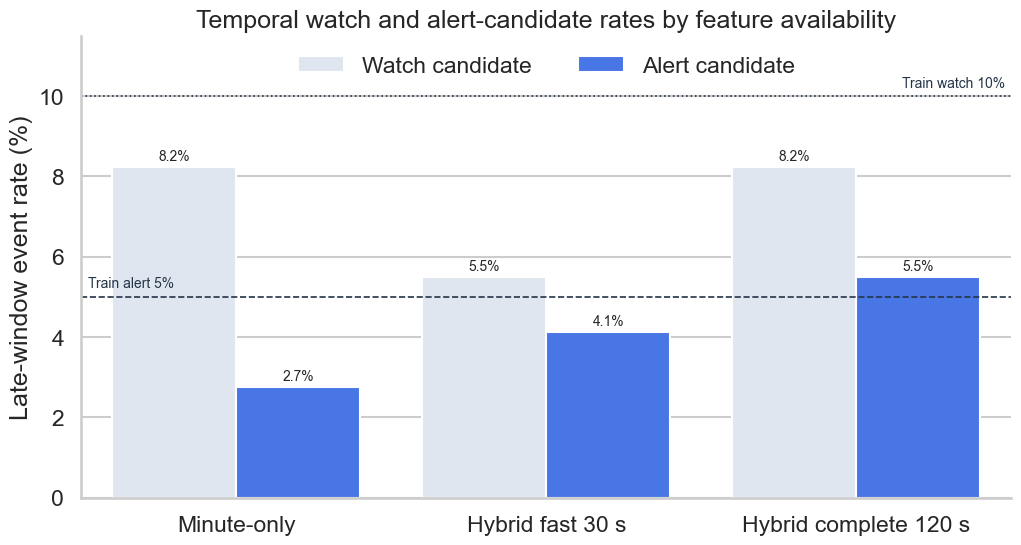

In [5]:
temporal_summary = (
    temporal_scored.groupby("model", sort=False)
    .agg(
        n_events=("anomaly_score", "size"),
        median_score=("anomaly_score", "median"),
        watch_rate_pct=("watch", lambda s: 100 * s.mean()),
        alert_rate_pct=("alert", lambda s: 100 * s.mean()),
        low_side_share_pct=("low_side_screen", lambda s: 100 * s.mean()),
        low_side_alert_rate_pct=("alert", lambda s: 100 * s[temporal_scored.loc[s.index, "low_side_screen"]].mean()),
        high_side_alert_rate_pct=("alert", lambda s: 100 * s[~temporal_scored.loc[s.index, "low_side_screen"]].mean()),
    )
    .reset_index()
)

by_machine_temporal = (
    temporal_scored.groupby(["model", "machine_number"])
    .agg(n_events=("anomaly_score", "size"), alert_rate_pct=("alert", lambda s: 100*s.mean()), median_score=("anomaly_score", "median"))
    .reset_index()
)
temporal_summary.to_csv(OUTPUT_ROOT / "temporal_model_comparison.csv", index=False)
by_machine_temporal.to_csv(OUTPUT_ROOT / "temporal_by_machine.csv", index=False)
display(temporal_summary)

plot_table = temporal_summary.melt(
    id_vars="model", value_vars=["watch_rate_pct", "alert_rate_pct"],
    var_name="threshold", value_name="rate_pct",
)
plot_table["threshold"] = plot_table["threshold"].map({
    "watch_rate_pct": "Watch candidate",
    "alert_rate_pct": "Alert candidate",
})
fig, ax = plt.subplots(figsize=(12, 6))
sns.barplot(data=plot_table, x="model", y="rate_pct", hue="threshold", palette=[PALETTE["light"], PALETTE["blue"]], ax=ax)
ax.axhline(100*(1-WATCH_QUANTILE), color=PALETTE["ink"], ls=":", lw=1.2)
ax.axhline(100*(1-ALERT_QUANTILE), color=PALETTE["ink"], ls="--", lw=1.2)
ax.text(2.48, 100*(1-WATCH_QUANTILE)+.15, "Train watch 10%", ha="right", va="bottom", fontsize=10, color=PALETTE["ink"])
ax.text(-.48, 100*(1-ALERT_QUANTILE)+.15, "Train alert 5%", ha="left", va="bottom", fontsize=10, color=PALETTE["ink"])
ax.set_title("Temporal watch and alert-candidate rates by feature availability")
ax.set_xlabel("")
ax.set_ylabel("Late-window event rate (%)")
ax.set_ylim(0, 11.5)
for container in ax.containers:
    ax.bar_label(container, fmt="%.1f%%", padding=3, fontsize=10)
ax.legend(title="", frameon=False, ncol=2, loc="upper center")
sns.despine()
savefig("01_temporal_model_comparison.png")
plt.show()

Alert rate ที่สูงหรือต่ำกว่า train reference ไม่ใช่ accuracy เพราะไม่มี failure label
แต่ใช้ดูว่า score distribution เปลี่ยนมากเพียงใดเมื่อเวลาเดินไปข้างหน้า และโมเดลใดไวต่อ late-window behavior มากกว่า.

### 6. Leave-one-machine-out portability

,model,machines,median_alert_pct,max_alert_pct,median_watch_pct
0,Minute-only,10,0.0,33.333333,0.0
1,Hybrid fast 30 s,10,0.0,33.333333,0.0
2,Hybrid complete 120 s,10,0.0,100.000000,0.0


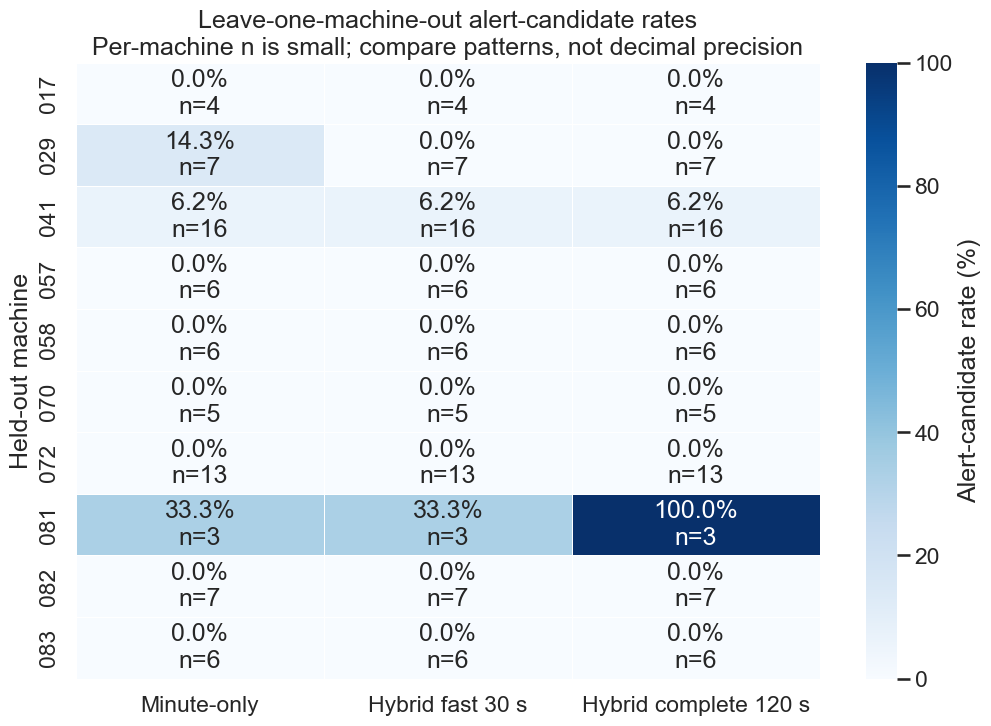

In [6]:
lomo_rows = []
for fold, held_out in enumerate(development_machines, start=1):
    fold_train = train_pdf[train_pdf["machine_number"] != held_out]
    fold_test = test_pdf[test_pdf["machine_number"] == held_out]
    for model_index, (model_name, spec) in enumerate(MODEL_SPECS.items()):
        bundle = fit_model(fold_train, spec["features"], RANDOM_STATE + fold*10 + model_index)
        scored = score_model(fold_test, bundle)
        lomo_rows.append({
            "model": model_name,
            "held_out_machine": held_out,
            "n_train": len(fold_train),
            "n_test": len(fold_test),
            "alert_rate_pct": 100 * scored["alert"].mean(),
            "watch_rate_pct": 100 * scored["watch"].mean(),
            "median_score": scored["anomaly_score"].median(),
        })

lomo = pd.DataFrame(lomo_rows)
lomo.to_csv(OUTPUT_ROOT / "lomo_model_comparison.csv", index=False)
lomo_summary = (
    lomo.groupby("model", sort=False)
    .agg(machines=("held_out_machine", "nunique"), median_alert_pct=("alert_rate_pct", "median"), max_alert_pct=("alert_rate_pct", "max"), median_watch_pct=("watch_rate_pct", "median"))
    .reset_index()
)
display(lomo_summary)

heat = lomo.pivot(index="held_out_machine", columns="model", values="alert_rate_pct").reindex(columns=list(MODEL_SPECS))
counts_heat = lomo.pivot(index="held_out_machine", columns="model", values="n_test").reindex(columns=list(MODEL_SPECS))
labels = heat.copy().astype(object)
for machine in heat.index:
    for model_name in heat.columns:
        labels.loc[machine, model_name] = f"{heat.loc[machine, model_name]:.1f}%\nn={int(counts_heat.loc[machine, model_name])}"

fig, ax = plt.subplots(figsize=(12, 8))
sns.heatmap(heat, cmap="Blues", vmin=0, annot=labels, fmt="", linewidths=.4, cbar_kws={"label": "Alert-candidate rate (%)"}, ax=ax)
ax.set_title("Leave-one-machine-out alert-candidate rates\nPer-machine n is small; compare patterns, not decimal precision")
ax.set_xlabel("")
ax.set_ylabel("Held-out machine")
savefig("02_lomo_model_comparison.png")
plt.show()

**LOMO scope:** fold นี้กัน held-out machine ออกจาก detector training แต่ minute relative features ยังอาศัย calibration profile
ของเครื่องนั้นที่สร้างจากช่วงต้น จึงเป็นการทดสอบ detector portability หลัง calibration ไม่ใช่ true cold-start ของเครื่องใหม่.

### 7. Sparse external/shadow machines

In [7]:
external_scored_parts = []
for model_name, bundle in bundles.items():
    scored = score_model(external_pdf, bundle)
    scored["model"] = model_name
    external_scored_parts.append(scored)

external_scored = pd.concat(external_scored_parts, ignore_index=True)
external_summary = (
    external_scored.groupby(["model", "machine_number"], sort=False)
    .agg(
        n_events=("anomaly_score", "size"),
        watch_rate_pct=("watch", lambda s: 100*s.mean()),
        alert_rate_pct=("alert", lambda s: 100*s.mean()),
        median_score=("anomaly_score", "median"),
    )
    .reset_index()
)
external_summary.to_csv(OUTPUT_ROOT / "external_sparse_model_comparison.csv", index=False)
display(external_summary)

,model,machine_number,n_events,watch_rate_pct,alert_rate_pct,median_score
0,Minute-only,022,4,0.000000,0.0,-0.104754
1,Minute-only,071,3,0.000000,0.0,-0.125840
2,Hybrid fast 30 s,022,4,0.000000,0.0,-0.119705
3,Hybrid fast 30 s,071,3,0.000000,0.0,-0.080207
4,Hybrid complete 120 s,022,4,0.000000,0.0,-0.116868
5,Hybrid complete 120 s,071,3,33.333333,0.0,-0.075369


MX022 และ MX071 ถูกใช้เป็น Test/Shadow เท่านั้นตามกติกาเดิม แต่มีรวมเพียง 7 events
จึงรายงานผลไว้เพื่อ trace behavior โดยไม่ใช้เลือกโมเดลหรือตีความเปอร์เซ็นต์ว่าเสถียร.

### 8. Seed stability and overlap between model decisions

In [8]:
stability_rows = []
reference_scores = {}
reference_alerts = {}
for model_name, spec in MODEL_SPECS.items():
    for iteration, seed in enumerate(range(RANDOM_STATE, RANDOM_STATE + 8)):
        bundle = fit_model(train_pdf, spec["features"], seed)
        scored = score_model(test_pdf, bundle)
        scores = scored["anomaly_score"].to_numpy()
        alerts = scored["alert"].to_numpy()
        if iteration == 0:
            reference_scores[model_name] = scores
            reference_alerts[model_name] = alerts
        union = np.logical_or(reference_alerts[model_name], alerts).sum()
        jaccard = np.logical_and(reference_alerts[model_name], alerts).sum() / union if union else 1.0
        stability_rows.append({
            "model": model_name, "seed": seed,
            "rank_rho_vs_reference": spearmanr(reference_scores[model_name], scores).statistic,
            "alert_jaccard_vs_reference": jaccard,
            "alert_rate_pct": 100 * alerts.mean(),
        })

stability = pd.DataFrame(stability_rows)
stability.to_csv(OUTPUT_ROOT / "seed_stability.csv", index=False)
stability_summary = (
    stability.groupby("model", sort=False)
    .agg(min_rank_rho=("rank_rho_vs_reference", "min"), median_alert_jaccard=("alert_jaccard_vs_reference", "median"), min_alert_rate_pct=("alert_rate_pct", "min"), max_alert_rate_pct=("alert_rate_pct", "max"))
    .reset_index()
)
display(stability_summary)

wide_scores = temporal_scored.pivot_table(index=["machine_number", "module", "event_at_minute"], columns="model", values="anomaly_score")
wide_alerts = temporal_scored.pivot_table(index=["machine_number", "module", "event_at_minute"], columns="model", values="alert")
agreement_rows = []
for model_name in ["Hybrid fast 30 s", "Hybrid complete 120 s"]:
    rho = spearmanr(wide_scores["Minute-only"], wide_scores[model_name]).statistic
    a = wide_alerts["Minute-only"].astype(bool).to_numpy()
    b = wide_alerts[model_name].astype(bool).to_numpy()
    union = np.logical_or(a, b).sum()
    agreement_rows.append({"comparison": f"Minute-only vs {model_name}", "score_rank_rho": rho, "alert_jaccard": np.logical_and(a, b).sum()/union if union else 1.0})
agreement = pd.DataFrame(agreement_rows)
display(agreement)

,model,min_rank_rho,median_alert_jaccard,min_alert_rate_pct,max_alert_rate_pct
0,Minute-only,0.985622,1.0,2.739726,2.739726
1,Hybrid fast 30 s,0.969672,1.0,2.739726,4.109589
2,Hybrid complete 120 s,0.971430,0.8,4.109589,6.849315


,comparison,score_rank_rho,alert_jaccard
0,Minute-only vs Hybrid fast 30 s,0.759098,0.666667
1,Minute-only vs Hybrid complete 120 s,0.550993,0.500000


### 9. Controlled response-shape sensitivity test — not a failure-label test

,model,median_score_change,new_alert_crossing_pct,stressed_alert_rate_pct
0,Minute-only,0.000000,0.000000,2.739726
1,Hybrid fast 30 s,0.035060,1.369863,5.479452
2,Hybrid complete 120 s,0.045533,5.479452,10.958904


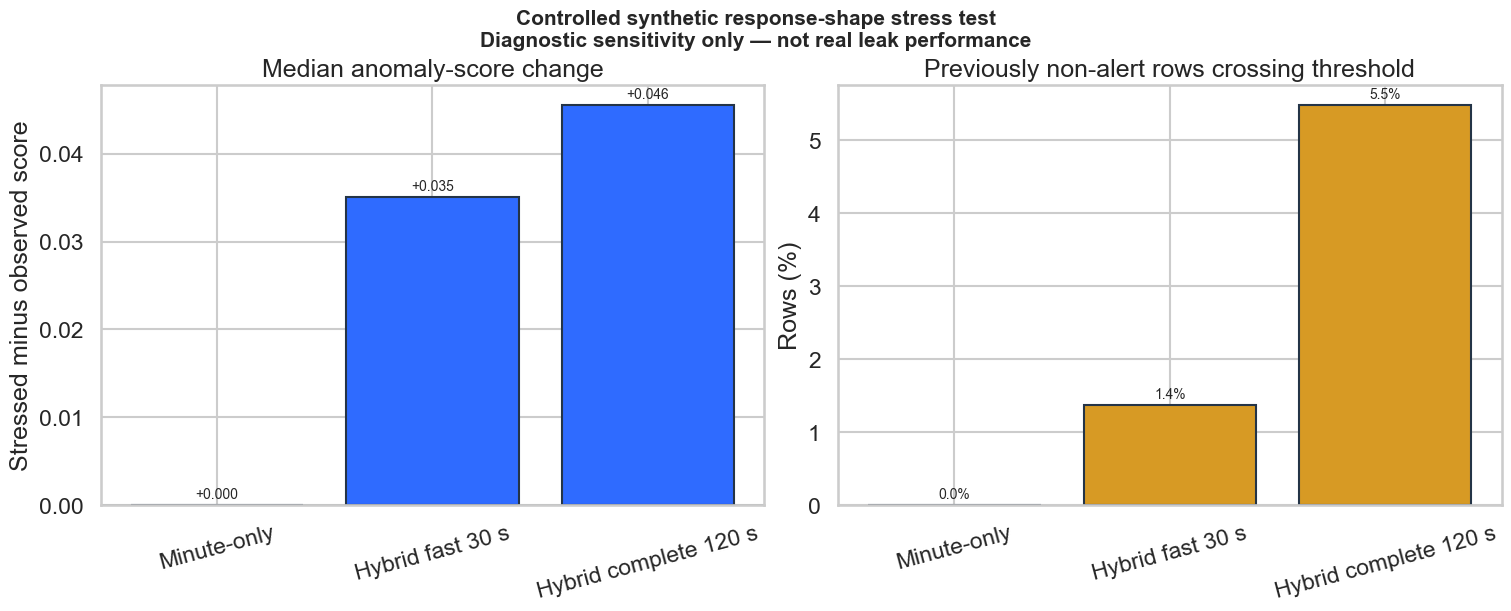

In [9]:
def perturb_response_shape(frame, train_reference, severity_iqr=1.5):
    changed = frame.copy()
    directions = {
        "hp2": -1, "lp2": -1, "temphi": -1, "templo": +1,
    }
    for target, direction in directions.items():
        for suffix in ["response_15s", "response_30s", "post_slope_30s", "response_60s", "response_120s"]:
            feature = f"{target}_{suffix}"
            if feature not in changed.columns:
                continue
            iqr = train_reference[feature].quantile(.75) - train_reference[feature].quantile(.25)
            if np.isfinite(iqr) and iqr > 0:
                changed[feature] = changed[feature] + direction * severity_iqr * iqr
        peak_feature = f"{target}_peak_abs"
        if peak_feature in changed.columns:
            iqr = train_reference[peak_feature].quantile(.75) - train_reference[peak_feature].quantile(.25)
            if np.isfinite(iqr) and iqr > 0:
                changed[peak_feature] = changed[peak_feature] + severity_iqr * iqr
    return changed

synthetic_test = perturb_response_shape(test_pdf, train_pdf)
sensitivity_rows = []
for model_name, bundle in bundles.items():
    original = score_model(test_pdf, bundle)
    stressed = score_model(synthetic_test, bundle)
    sensitivity_rows.append({
        "model": model_name,
        "median_score_change": float(np.median(stressed["anomaly_score"] - original["anomaly_score"])),
        "new_alert_crossing_pct": 100 * np.mean((~original["alert"]) & stressed["alert"]),
        "stressed_alert_rate_pct": 100 * stressed["alert"].mean(),
    })

sensitivity = pd.DataFrame(sensitivity_rows)
sensitivity.to_csv(OUTPUT_ROOT / "synthetic_response_sensitivity.csv", index=False)
display(sensitivity)

fig, axes = plt.subplots(1, 2, figsize=(15, 6), constrained_layout=True)
bars1 = axes[0].bar(sensitivity["model"], sensitivity["median_score_change"], color=PALETTE["blue"], edgecolor=PALETTE["ink"])
axes[0].axhline(0, color=PALETTE["ink"], lw=1)
axes[0].bar_label(bars1, fmt="%+.3f", padding=3, fontsize=10)
axes[0].set_title("Median anomaly-score change")
axes[0].set_ylabel("Stressed minus observed score")
axes[0].tick_params(axis="x", rotation=15)
bars2 = axes[1].bar(sensitivity["model"], sensitivity["new_alert_crossing_pct"], color=PALETTE["gold"], edgecolor=PALETTE["ink"])
axes[1].bar_label(bars2, fmt="%.1f%%", padding=3, fontsize=10)
axes[1].set_title("Previously non-alert rows crossing threshold")
axes[1].set_ylabel("Rows (%)")
axes[1].tick_params(axis="x", rotation=15)
fig.suptitle("Controlled synthetic response-shape stress test\nDiagnostic sensitivity only — not real leak performance", fontsize=15, fontweight="bold")
savefig("03_synthetic_response_sensitivity.png")
plt.show()

การทดสอบนี้เปลี่ยนเฉพาะ response-shape features โดยคง minute-only inputs เดิม
จึงตอบคำถามว่าโมเดล “มองเห็น” behavior ที่ถูกบีบหายในการ aggregate รายหนึ่งนาทีหรือไม่
แต่ห้ามใช้ผลนี้แทน precision/recall จาก technician-confirmed failures.

### 10. Server benchmark and operating cost

,model,features,available_after_s,batch_size,p50_inference_ms,p95_inference_ms,model_bundle_kib
0,Minute-only,19,0,1,40.43475,52.841790,1249.743164
1,Minute-only,19,0,8,34.19935,40.258190,1249.743164
2,Minute-only,19,0,64,37.26520,68.695190,1249.743164
3,Hybrid fast 30 s,36,30,1,35.60730,47.898880,1239.841797
4,Hybrid fast 30 s,36,30,8,36.15050,41.106910,1239.841797
5,Hybrid fast 30 s,36,30,64,35.87085,41.697210,1239.841797
6,Hybrid complete 120 s,58,120,1,36.33970,42.400335,1354.987305
7,Hybrid complete 120 s,58,120,8,36.81315,40.683275,1354.987305
8,Hybrid complete 120 s,58,120,64,36.62460,43.215270,1354.987305


,Server estimate,Value
0,observed_machine_days,336.000000
1,compressed_raw_mib_per_machine_day,1.972253
2,estimated_19_machine_raw_gib_per_30d_at_observ...,1.097836
3,candidate_events_per_machine_day,8.842262
4,clean_events_per_machine_day,0.723214
5,continuous_module_scores_per_second_for_19_mac...,2.533333
6,estimated_180s_ring_buffer_payload_mib,2.504883


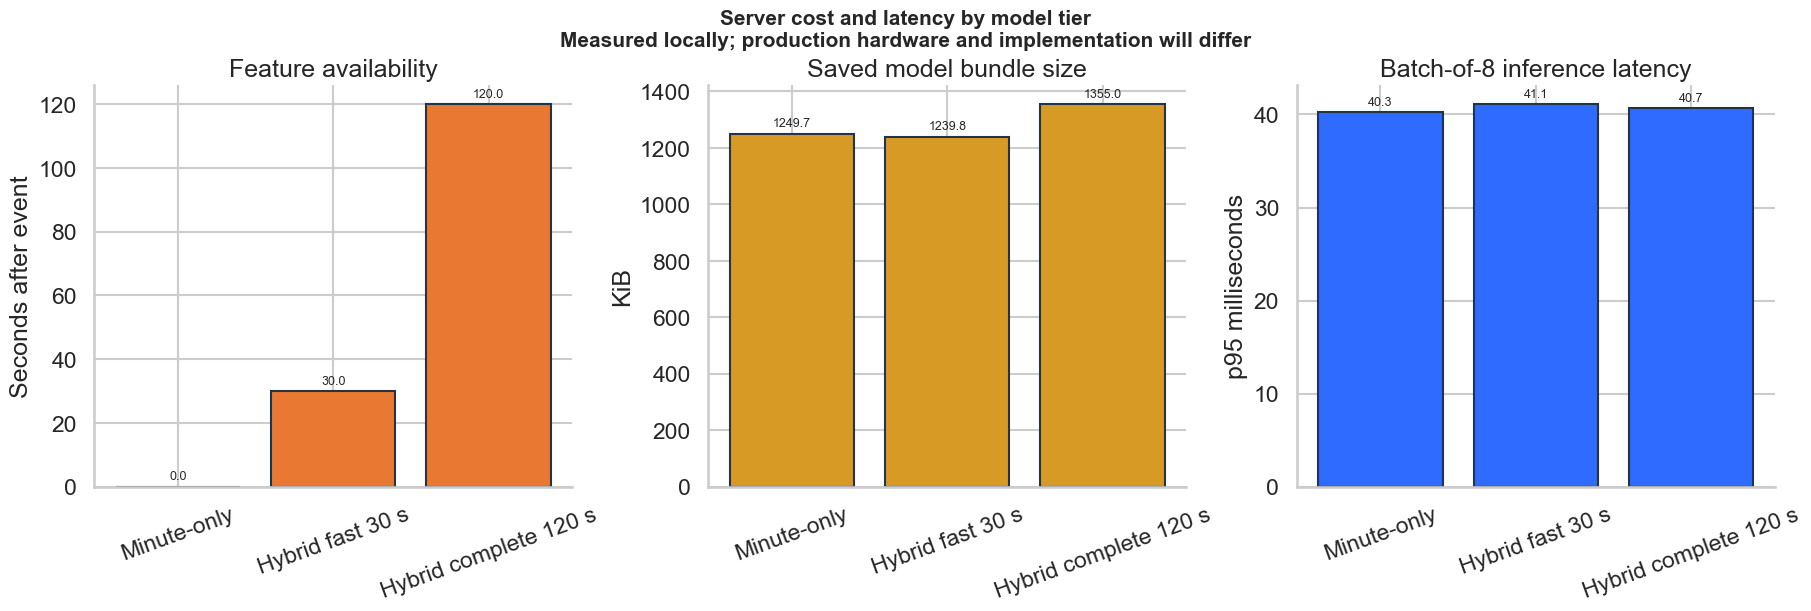

In [10]:
def transform_for_bundle(frame, bundle):
    fill = pd.Series(bundle["fill_values"])
    matrix, _ = clean_matrix(frame, bundle["features"], fill)
    return bundle["scaler"].transform(matrix)

benchmark_rows = []
for model_name, bundle in bundles.items():
    model_file = MODEL_ROOT / f"{model_name.lower().replace(' ', '_').replace('-', '_')}.joblib"
    for batch_size in [1, 8, 64]:
        sample = pd.concat([test_pdf] * (math.ceil(batch_size / len(test_pdf)) + 1), ignore_index=True).iloc[:batch_size]
        transformed = transform_for_bundle(sample, bundle)
        bundle["detector"].decision_function(transformed)
        timings = []
        for _ in range(40):
            start = time.perf_counter()
            bundle["detector"].decision_function(transformed)
            timings.append((time.perf_counter() - start) * 1000)
        benchmark_rows.append({
            "model": model_name,
            "features": len(bundle["features"]),
            "available_after_s": bundle["available_after_s"],
            "batch_size": batch_size,
            "p50_inference_ms": float(np.median(timings)),
            "p95_inference_ms": float(np.percentile(timings, 95)),
            "model_bundle_kib": model_file.stat().st_size / 1024,
        })

benchmark = pd.DataFrame(benchmark_rows)
benchmark.to_csv(OUTPUT_ROOT / "deployment_benchmark.csv", index=False)

inventory = pd.read_csv(INVENTORY_FILE, dtype={"machine_number": "string"})
raw_bytes = sum(path.stat().st_size for path in DATA_ROOT.rglob("*.parquet"))
observed_machine_days = inventory["observed_days"].sum()
with open(CADENCE_FILE, encoding="utf-8") as f:
    cadence = json.load(f)

server_estimates = {
    "observed_machine_days": int(observed_machine_days),
    "compressed_raw_mib_per_machine_day": raw_bytes / 1024**2 / observed_machine_days,
    "estimated_19_machine_raw_gib_per_30d_at_observed_density": raw_bytes / 1024**3 / observed_machine_days * 19 * 30,
    "candidate_events_per_machine_day": cadence["candidate_event_count"] / observed_machine_days,
    "clean_events_per_machine_day": cadence["clean_event_count"] / observed_machine_days,
    "continuous_module_scores_per_second_for_19_machines": 19 * 8 / 60,
    "estimated_180s_ring_buffer_payload_mib": 180 * 19 * 8 * 12 * 8 / 1024**2,
}
display(benchmark)
display(pd.DataFrame(server_estimates.items(), columns=["Server estimate", "Value"]))

batch8 = benchmark[benchmark["batch_size"] == 8].copy()
fig, axes = plt.subplots(1, 3, figsize=(18, 6), constrained_layout=True)
for ax, field, title, ylabel, color in [
    (axes[0], "available_after_s", "Feature availability", "Seconds after event", PALETTE["orange"]),
    (axes[1], "model_bundle_kib", "Saved model bundle size", "KiB", PALETTE["gold"]),
    (axes[2], "p95_inference_ms", "Batch-of-8 inference latency", "p95 milliseconds", PALETTE["blue"]),
]:
    bars = ax.bar(batch8["model"], batch8[field], color=color, edgecolor=PALETTE["ink"])
    ax.bar_label(bars, fmt="%.1f", padding=3, fontsize=9)
    ax.set_title(title)
    ax.set_ylabel(ylabel)
    ax.tick_params(axis="x", rotation=20)
    sns.despine(ax=ax)
fig.suptitle("Server cost and latency by model tier\nMeasured locally; production hardware and implementation will differ", fontsize=15, fontweight="bold")
savefig("04_server_cost_tradeoff.png")
plt.show()

## Deployment recommendation

### Recommended production design: two-stage, event-driven hybrid

```text
1-second ingest
   ├─ validate timestamp / missingness / state / SV
   ├─ keep a 180-second circular buffer per machine × module
   ├─ every minute → Minute-only continuous score
   └─ clean ChangeValve detected
         ├─ +30 s  → Hybrid fast watch score
         └─ +120 s → Hybrid complete confirmation score
                         ↓
          persistence + evidence fusion + technician review
```

ไม่ควรให้ complete model แทน minute model ทันที เพราะ event coverage ยังแคบและ complete feature มี latency 120 วินาที
ให้ minute model เฝ้าตลอด ส่วน second-derived model เป็น specialist ที่อ่าน dynamic response เฉพาะ event.

### ข้อดี

- รักษา onset, peak, delay และ valve hunting ที่ข้อมูลรายนาทีมองไม่เห็น
- ประมวลผลแบบ event-driven จึงไม่ต้อง score feature 1 วินาทีทุกแถว
- สามารถแจ้ง watch หลัง 30 วินาที และยืนยันด้วย complete response หลัง 120 วินาที
- เก็บ feature vector และ trace เฉพาะ event/alert ลด storage เมื่อเทียบกับเก็บ raw 1 วินาทีตลอดไป

### ข้อเสียและความเสี่ยง

- ต้องเป็นระบบ stateful; server restart, timestamp gap และข้อมูลมาช้าสามารถทำให้ window ไม่ครบ
- complete score ช้า 1–2 นาที และห้ามนำไป timestamp เป็นผลที่รู้ตั้งแต่นาทีเริ่ม event
- training events ยังน้อย, เป็น SV Off และแทบทั้งหมดเป็น closing จึงยังไม่รองรับ SV On/opening อย่างน่าเชื่อถือ
- ไม่มี failure label จึงยังวัด false-positive/recall จริงไม่ได้
- recipe/load/facility-water context ยังขาด ทำให้ model อาจจับ operating context แทน health

### Production safeguards

1. Version calibration profile, feature code และ model bundle พร้อมกัน
2. เก็บ `feature_ready_at` แยกจาก `event_at` เพื่อกัน look-ahead leakage
3. หาก window ขาด, SV เปลี่ยน, homing/stop/emergency หรือ timestamp gap ให้ `abstain` ไม่ฝืน score
4. ใช้ persistence หลาย event/หลาย cycle ก่อนยกระดับ alert
5. บันทึก 180-second trace เฉพาะ alert เพื่อให้ช่างตรวจย้อนหลัง
6. เริ่ม shadow mode และวัด false alarms/day, alert persistence และ technician confirmation ก่อน production alert

## Takeaways

### 11. Export summary and QA evidence

In [11]:
comparison = temporal_summary.merge(
    lomo_summary[["model", "median_alert_pct", "max_alert_pct"]], on="model", how="left"
).merge(
    stability_summary[["model", "min_rank_rho", "median_alert_jaccard"]], on="model", how="left"
).merge(
    sensitivity[["model", "median_score_change", "new_alert_crossing_pct"]], on="model", how="left"
).merge(
    benchmark[benchmark["batch_size"] == 8][["model", "features", "available_after_s", "p95_inference_ms", "model_bundle_kib"]], on="model", how="left"
)
comparison["train_rows_per_feature"] = len(train_pdf) / comparison["features"]
comparison.to_csv(OUTPUT_ROOT / "model_comparison_summary.csv", index=False)

analysis_summary = {
    "source_period": {
        "start": str(event_pdf["event_at_minute"].min()),
        "end": str(event_pdf["event_at_minute"].max()),
        "timezone": "not encoded in source timestamps",
    },
    "event_rows": {
        "closing_input": int(len(events)),
        "joined": int(len(event_pdf)),
        "train": int(len(train_pdf)),
        "temporal_test": int(len(test_pdf)),
        "external_sparse": int(len(external_pdf)),
        "development_machines": development_machines,
        "external_sparse_machines": external_sparse_machines,
    },
    "models": comparison.to_dict(orient="records"),
    "external_sparse_results": external_summary.to_dict(orient="records"),
    "server_estimates": server_estimates,
    "interpretation": "Unsupervised comparison without technician-confirmed failure labels; alert rates are stability diagnostics, not accuracy.",
}
with open(OUTPUT_ROOT / "analysis_summary.json", "w", encoding="utf-8") as f:
    json.dump(analysis_summary, f, ensure_ascii=False, indent=2)

display(comparison)
display(Markdown(f'''
### Executed conclusion

- ใช้ closing events {len(event_pdf):,} rows หลัง backward join; train {len(train_pdf):,}, temporal test {len(test_pdf):,}, sparse external {len(external_pdf):,}
- โมเดลทั้งสามถูกเทรนและบันทึกแล้ว โดย feature พร้อมที่ 0/30/120 วินาทีตามลำดับ
- แนะนำ **Minute-only continuous monitor + Hybrid fast watch + Hybrid complete confirmation**
- ต้นทุน inference ไม่ใช่ bottleneck หลัก; ความเสี่ยงหลักคือ window/state correctness, data gaps, latency และ training coverage
- สถานะผล: **Share with caveats / shadow-mode ready** แต่ยังไม่พร้อมอ้างว่าเป็น leak classifier
'''))

print("Saved outputs:")
for path in sorted(OUTPUT_ROOT.rglob("*")):
    if path.is_file():
        print("-", path.relative_to(PROJECT_ROOT))

,model,n_events,median_score,watch_rate_pct,alert_rate_pct,low_side_share_pct,low_side_alert_rate_pct,high_side_alert_rate_pct,median_alert_pct,max_alert_pct,min_rank_rho,median_alert_jaccard,median_score_change,new_alert_crossing_pct,features,available_after_s,p95_inference_ms,model_bundle_kib,train_rows_per_feature
0,Minute-only,73,-0.133574,8.219178,2.739726,1.369863,0.0,2.777778,0.0,33.333333,0.985622,1.0,0.000000,0.000000,19,0,40.258190,1249.743164,8.421053
1,Hybrid fast 30 s,73,-0.135563,5.479452,4.109589,1.369863,0.0,4.166667,0.0,33.333333,0.969672,1.0,0.035060,1.369863,36,30,41.106910,1239.841797,4.444444
2,Hybrid complete 120 s,73,-0.125669,8.219178,5.479452,1.369863,0.0,5.555556,0.0,100.000000,0.971430,0.8,0.045533,5.479452,58,120,40.683275,1354.987305,2.758621



### Executed conclusion

- ใช้ closing events 240 rows หลัง backward join; train 160, temporal test 73, sparse external 7
- โมเดลทั้งสามถูกเทรนและบันทึกแล้ว โดย feature พร้อมที่ 0/30/120 วินาทีตามลำดับ
- แนะนำ **Minute-only continuous monitor + Hybrid fast watch + Hybrid complete confirmation**
- ต้นทุน inference ไม่ใช่ bottleneck หลัก; ความเสี่ยงหลักคือ window/state correctness, data gaps, latency และ training coverage
- สถานะผล: **Share with caveats / shadow-mode ready** แต่ยังไม่พร้อมอ้างว่าเป็น leak classifier


Saved outputs:
- notebooks\outputs\ht9046mx_ml_second_comparison\analysis_summary.json
- notebooks\outputs\ht9046mx_ml_second_comparison\deployment_benchmark.csv
- notebooks\outputs\ht9046mx_ml_second_comparison\external_sparse_model_comparison.csv
- notebooks\outputs\ht9046mx_ml_second_comparison\figures\01_temporal_model_comparison.png
- notebooks\outputs\ht9046mx_ml_second_comparison\figures\02_lomo_model_comparison.png
- notebooks\outputs\ht9046mx_ml_second_comparison\figures\03_synthetic_response_sensitivity.png
- notebooks\outputs\ht9046mx_ml_second_comparison\figures\04_server_cost_tradeoff.png
- notebooks\outputs\ht9046mx_ml_second_comparison\lomo_model_comparison.csv
- notebooks\outputs\ht9046mx_ml_second_comparison\model_comparison_summary.csv
- notebooks\outputs\ht9046mx_ml_second_comparison\models\hybrid_complete_120_s.joblib
- notebooks\outputs\ht9046mx_ml_second_comparison\models\hybrid_fast_30_s.joblib
- notebooks\outputs\ht9046mx_ml_second_comparison\models\minute_only.

## QA Checklist

- [x] ใช้ event rows ชุดเดียวกันเปรียบเทียบทั้งสามโมเดล
- [x] split ตามเวลา ไม่สุ่ม train/test
- [x] backward join เท่านั้นและบันทึก join gap
- [x] scaler, missing-value fill และ threshold fit จาก train เท่านั้น
- [x] LOMO กัน detector ของเครื่องทดสอบออกจาก training
- [x] แยก synthetic sensitivity ออกจาก real-data validation อย่างชัดเจน
- [x] ไม่เรียก `Hp_2nd < 180 psi` หรือ `Hp_2nd > 230 psi` ว่า failure label
- [x] รายงาน sample size และข้อจำกัด SV Off/closing-only
- [x] วัด model size และ inference latency จริงใน environment ที่ execute Notebook